# 05 — Modèles

X, Y d'une station (`src/features.py`), choix des carreaux, trois modèles (`src/modeles.py` : gradient boosting par échéance, réseau TensorFlow, réseau PyTorch), choix des hyperparamètres par validation croisée. Tout est compté depuis t, l'instant où l'on prévoit.

In [7]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

_racine = Path.cwd()
while not (_racine / "src").exists() and _racine != _racine.parent:
    _racine = _racine.parent
if str(_racine) not in sys.path:
    sys.path.insert(0, str(_racine))

import pandas as pd
import matplotlib.pyplot as plt
from src.features import Features
from src.modeles import Modele, choisir_parametres, PAR_DEFAUT, entrainer, resultats, contenu_cache, vider_cache

ID = "52a0c9cee4b03f58295e6f8a"     # La Clapière (Durance à Embrun)
TEST = [2023, 2024]                  # années de test, regardées seulement à la fin
# réglages des réseaux (keras et torch) pour tout le notebook : ceux des modèles en cache (11/10/2026) ;
# défauts : PAR_DEFAUT["torch"] ; changer une valeur = d'autres modèles, réentraînés
RESEAU = dict(couches=(256, 256, 128),     # neurones par couche, ex. (64, 32) pour un petit réseau
              dropout=(0.2, 0.2, 0.1),     # un par couche, ou un seul nombre pour toutes, ex. 0.3
              l2=1e-3,                     # pénalité des poids
              lot=64)                      # taille des lots (plus gros = plus rapide sur carte graphique)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 1. Choisir les carreaux

Glouton sur les attributs BasinATLAS (aucun appel) : chaque morceau de l'amont doit avoir un carreau choisi qui lui ressemble (neige, pluie, position), chaque morceau compte pour l'eau qu'il envoie à la rivière. Tout est réglable : `criteres={"snw_pc_syr": 1, "pre_mm_syr": 1, "position": 1}`, `poids="run_mm_syr"` ou `None`, `dedans_min`, `largeur`, `seuil`, `k_max`.

7 carreaux retenus : [835931, 841112, 838522, 830767, 846307, 841113, 833346]


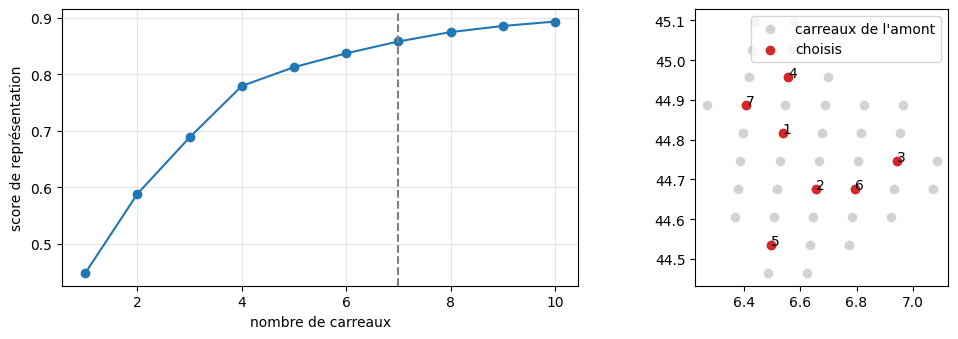

,rang,carreau,gain,score,retenu,part_eau,lon_centre,lat_centre,snw_pc_syr,pre_mm_syr
0,1,835931,0.448434,0.448434,True,0.0384,6.537867,44.815465,38.7,1379.8
1,2,841112,0.140245,0.588679,True,0.0365,6.656394,44.674867,33.5,1256.5
2,3,838522,0.099867,0.688546,True,0.0406,6.944444,44.745166,44.0,1427.3
3,4,830767,0.090871,0.779416,True,0.0379,6.558140,44.956062,42.2,1434.6
4,5,846307,0.033247,0.812664,True,0.0212,6.497696,44.534270,32.0,1177.0
5,6,841113,0.024466,0.837130,True,0.0369,6.795069,44.674867,37.1,1332.5
6,7,833346,0.020917,0.858046,True,0.0347,6.408669,44.885763,44.0,1475.0
7,8,835932,0.016591,0.874637,False,0.0367,6.676971,44.815465,35.5,1319.8
8,9,830768,0.010840,0.885477,False,0.0259,6.697674,44.956062,43.9,1441.5
9,10,841111,0.007757,0.893234,False,0.0373,6.517720,44.674867,32.7,1243.9


In [8]:
F = Features(ID, "2010-01-01", "2025-12-31", filtre=False)
choix = F.choisir_carreaux()
# ex. : F.choisir_carreaux(criteres={"snw_pc_syr": 1, "pre_mm_syr": 1})   (sans la position)
CARREAUX = choix.loc[choix["retenu"], "carreau"].tolist()
print(len(CARREAUX), "carreaux retenus :", CARREAUX)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.5))
a1.plot(choix["rang"], choix["score"], "o-"); a1.axvline(len(CARREAUX), ls="--", c="grey")
a1.set_xlabel("nombre de carreaux"); a1.set_ylabel("score de représentation"); a1.grid(alpha=0.3)
a2.scatter(F.carreaux["lon_centre"], F.carreaux["lat_centre"], c="lightgrey", label="carreaux de l'amont")
r = choix[choix["retenu"]]
a2.scatter(r["lon_centre"], r["lat_centre"], c="C3", label="choisis")
for _, l in r.iterrows():
    a2.annotate(int(l["rang"]), (l["lon_centre"], l["lat_centre"]))
a2.set_aspect(1 / 0.71); a2.legend(); plt.tight_layout(); plt.show()
choix

## 2. X et Y

On part de X et Y vides, on ajoute (ou retire) ce qu'on veut, puis `construire()` lit les caches. `F.X.columns` / `F.Y.columns` montrent ce qui est prévu avant de construire. Toute la météo est déjà en cache : aucun appel Open-Meteo.

In [9]:
F.retirer(); F.retirer_cibles()        # repartir de zéro : la cellule peut être relancée sans rien doubler
F.ajouter_meteo(["precipitation", "temperature_2m", "snow_depth"], carreaux=CARREAUX,
                depuis="24h", pas="12h", jusqu_a="5D")
F.ajouter_debit(depuis="24h", pas="1h")
F.ajouter_date()
F.ajouter_cible("5D", "8h")
# ex. : F.retirer(carreau=830767) ; F.retirer(variable="temperature_2m") ; F.retirer_colonnes("debit_passe_1h_t-23h")
print("prévu  X :", F.X.shape[1], "colonnes  Y :", F.Y.shape[1], "échéances")
print(F.entrees.head())

F.construire()
print("X :", F.X.shape, " Y :", F.Y.shape, " années :", F.annees())

prévu  X : 280 colonnes  Y : 15 échéances
    type carreau        variable depuis jusqu_a  pas avant_echeance  \
0  meteo  835931   precipitation    24h      5D  12h           None   
1  meteo  835931  temperature_2m    24h      5D  12h           None   
2  meteo  835931      snow_depth    24h      5D  12h           None   
3  meteo  841112   precipitation    24h      5D  12h           None   
4  meteo  841112  temperature_2m    24h      5D  12h           None   

  apres_echeance  
0             0h  
1             0h  
2             0h  
3             0h  
4             0h  
X : (115233, 280)  Y : (115233, 15)  années : [2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]


## 3. Entraîner les trois modèles (cellule longue)

`entrainer` entraîne, note sur le test et ENREGISTRE chaque modèle dans `data/cache/modeles/`. Un modèle déjà entraîné avec la même recette, le même test et les mêmes réglages est relu (0 s, sans même construire X). Réglages modifiables : `entrainer(F, TEST, "torch", couches=(128, 128), lot=512)`.

In [12]:
CLES = {}
for nom in ["gradient_boosting", "keras", "torch"]:
    CLES[nom] = entrainer(F, TEST, nom, etiquette=f"{nom}, {len(CARREAUX)} carreaux",
                          **({} if nom == "gradient_boosting" else RESEAU)).cle
CLES

gradient_boosting déjà entraîné (clé 010b47e351d2) : relu depuis le cache
keras déjà entraîné (clé e91ebb690ef9) : relu depuis le cache
torch déjà entraîné (clé 560ae32a2672) : relu depuis le cache


{'gradient_boosting': '010b47e351d2',
 'keras': 'e91ebb690ef9',
 'torch': '560ae32a2672'}

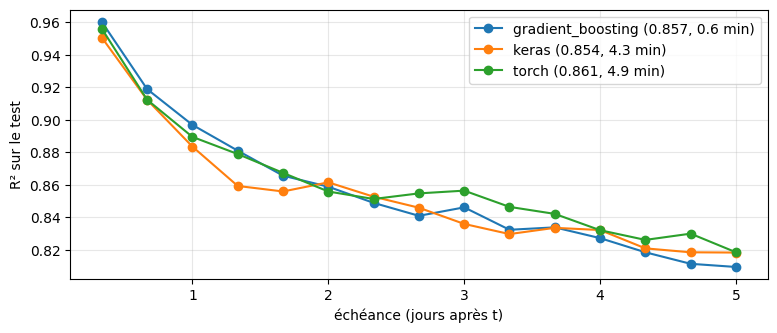

In [11]:
# graphiques : ne lisent que le cache (relançables après un redémarrage, sans réentraîner)
R = {nom: resultats(cle) for nom, cle in CLES.items()}
plt.figure(figsize=(9, 3.5))
for nom, r in R.items():
    heures = [int(col.split("t+")[1][:-1]) for col in r["r2"].index]
    plt.plot([h / 24 for h in heures], r["r2"].values, "o-",
             label=f"{nom} ({r['fiche']['r2_moyen']:.3f}, {r['fiche']['duree_s'] / 60:.1f} min)")
plt.xlabel("échéance (jours après t)"); plt.ylabel("R² sur le test"); plt.grid(alpha=0.3); plt.legend()
plt.show()

## 3.5 on augmente le nombre de variables météo

7 carreaux retenus : [835931, 841112, 838522, 830767, 846307, 841113, 833346]


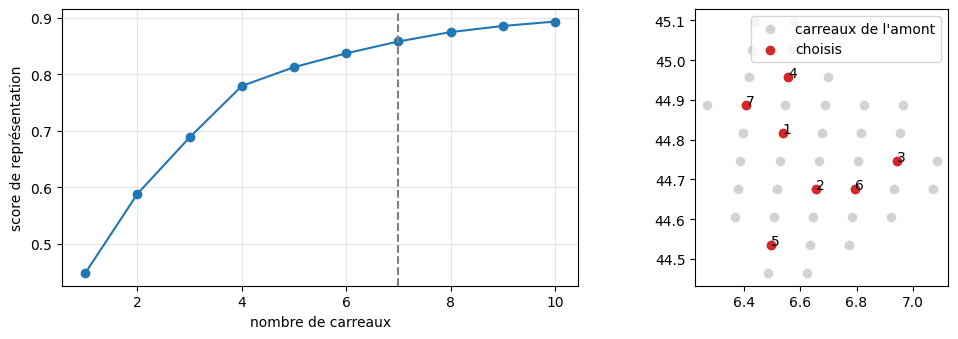

,rang,carreau,gain,score,retenu,part_eau,lon_centre,lat_centre,snw_pc_syr,pre_mm_syr
0,1,835931,0.448434,0.448434,True,0.0384,6.537867,44.815465,38.7,1379.8
1,2,841112,0.140245,0.588679,True,0.0365,6.656394,44.674867,33.5,1256.5
2,3,838522,0.099867,0.688546,True,0.0406,6.944444,44.745166,44.0,1427.3
3,4,830767,0.090871,0.779416,True,0.0379,6.558140,44.956062,42.2,1434.6
4,5,846307,0.033247,0.812664,True,0.0212,6.497696,44.534270,32.0,1177.0
5,6,841113,0.024466,0.837130,True,0.0369,6.795069,44.674867,37.1,1332.5
6,7,833346,0.020917,0.858046,True,0.0347,6.408669,44.885763,44.0,1475.0
7,8,835932,0.016591,0.874637,False,0.0367,6.676971,44.815465,35.5,1319.8
8,9,830768,0.010840,0.885477,False,0.0259,6.697674,44.956062,43.9,1441.5
9,10,841111,0.007757,0.893234,False,0.0373,6.517720,44.674867,32.7,1243.9


In [13]:
F2 = Features(ID, "2010-01-01", "2025-12-31", filtre=False)
choix = F.choisir_carreaux()
# ex. : F.choisir_carreaux(criteres={"snw_pc_syr": 1, "pre_mm_syr": 1})   (sans la position)
CARREAUX = choix.loc[choix["retenu"], "carreau"].tolist()
print(len(CARREAUX), "carreaux retenus :", CARREAUX)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.5))
a1.plot(choix["rang"], choix["score"], "o-"); a1.axvline(len(CARREAUX), ls="--", c="grey")
a1.set_xlabel("nombre de carreaux"); a1.set_ylabel("score de représentation"); a1.grid(alpha=0.3)
a2.scatter(F.carreaux["lon_centre"], F.carreaux["lat_centre"], c="lightgrey", label="carreaux de l'amont")
r = choix[choix["retenu"]]
a2.scatter(r["lon_centre"], r["lat_centre"], c="C3", label="choisis")
for _, l in r.iterrows():
    a2.annotate(int(l["rang"]), (l["lon_centre"], l["lat_centre"]))
a2.set_aspect(1 / 0.71); a2.legend(); plt.tight_layout(); plt.show()
choix

In [16]:
F2.retirer(); F2.retirer_cibles()      # repartir de zéro : la cellule peut être relancée sans rien doubler
F2.ajouter_meteo(["temperature_2m", "snow_depth", "shortwave_radiation",
               "rain", "snowfall", "soil_moisture_7_to_28cm"], carreaux=CARREAUX,
                depuis="24h", pas="12h", jusqu_a="5D")
F2.ajouter_debit(depuis="24h", pas="1h")
F2.ajouter_date()
F2.ajouter_cible("5D", "8h")
# ex. : F2.retirer(carreau=830767) ; F2.retirer(variable="temperature_2m") ; F2.retirer_colonnes("debit_passe_1h_t-23h")
print("prévu  X :", F2.X.shape[1], "colonnes  Y :", F2.Y.shape[1], "échéances")
print(F2.entrees.head())

F2.construire()
print("X :", F2.X.shape, " Y :", F2.Y.shape, " années :", F2.annees())

prévu  X : 532 colonnes  Y : 30 échéances
    type carreau                 variable depuis jusqu_a  pas avant_echeance  \
0  meteo  835931           temperature_2m    24h      5D  12h           None   
1  meteo  835931               snow_depth    24h      5D  12h           None   
2  meteo  835931      shortwave_radiation    24h      5D  12h           None   
3  meteo  835931                     rain    24h      5D  12h           None   
4  meteo  835931  soil_moisture_7_to_28cm    24h      5D  12h           None   

  apres_echeance  
0             0h  
1             0h  
2             0h  
3             0h  
4             0h  
X : (111886, 532)  Y : (111886, 30)  années : [2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]


In [17]:
# réglages des réseaux : RESEAU (cellule 1)
DUREE_MAX = {"gradient_boosting": "15min", "keras": "15min", "torch": "15min"}

CLES2 = {}
for nom in ["gradient_boosting", "keras", "torch"]:
    reglages = {} if nom == "gradient_boosting" else RESEAU
    etiquette = f"{nom}, 6 variables" + ("" if nom == "gradient_boosting" else f", {RESEAU['couches']}")
    CLES2[nom] = entrainer(F2, TEST, nom, etiquette=etiquette, duree_max=DUREE_MAX[nom], **reglages).cle
CLES2


gradient_boosting : échéances: 100%|██████████| 30/30 [15:01<00:00, 30.06s/it]


gradient_boosting : arrêté par duree_max=15min (meilleur état gardé), R² moyen 0.734


keras : époques:  12%|█▏        | 37/300 [01:52<13:21,  3.05s/epoch, loss=0.0922, val_loss=0.143, learning_rate=0.000188]


torch : époques:  10%|█         | 30/300 [02:28<22:20,  4.97s/it, validation=0.0944]


{'gradient_boosting': '94c8e3b0fa93',
 'keras': '4cc62346b93c',
 'torch': '26bb65dc481e'}

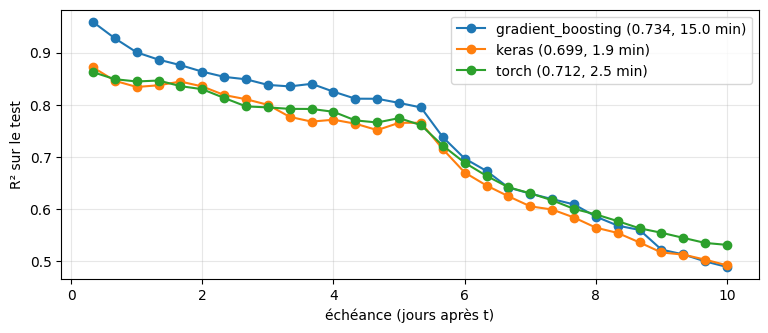

In [18]:
# graphiques : ne lisent que le cache (relançables après un redémarrage, sans réentraîner)
R2 = {nom: resultats(cle) for nom, cle in CLES2.items()}
plt.figure(figsize=(9, 3.5))
for nom, r in R2.items():
    heures = [int(col.split("t+")[1][:-1]) for col in r["r2"].index]
    plt.plot([h / 24 for h in heures], r["r2"].values, "o-",
             label=f"{nom} ({r['fiche']['r2_moyen']:.3f}, {r['fiche']['duree_s'] / 60:.1f} min)")
plt.xlabel("échéance (jours après t)"); plt.ylabel("R² sur le test"); plt.grid(alpha=0.3); plt.legend()
plt.show()

In [ ]:
# explorer le test : curseur « Début » (fenêtre de FENETRE), curseur « Échéance », clic sur un modèle pour le masquer
from src.graphes import explorer
FENETRE = "30D"
explorer(CLES2, fenetre=FENETRE, titre="La Clapière — 6 variables")
# page HTML autonome : explorer(CLES2, fenetre=FENETRE, fichier="../data/outputs/clapiere.html")


## 3.6 X réduit : un seul seuil pour l'espace et le temps

Même expérience que 3.5 (même débit passé, même date, mêmes échéances, mêmes réglages, 15 minutes par modèle), mais la météo de X, la table d'entrée du modèle, est choisie d'après les mesures du notebook 03 (section 8) au lieu de 7 carreaux au pas de 12 h. Les précipitations (pluie + neige) remplacent pluie et neige séparées : la température suffit au modèle pour faire la différence.

Un seul seuil `SEUIL` pour tout :

- **en espace**, pour chaque variable, on prend des carreaux un par un : à chaque tour, celui qui, ajouté aux carreaux déjà pris, reconstruit le mieux les 41 carreaux (par combinaison linéaire), jusqu'à garder `SEUIL` de la variance. Si $x$ est la série d'un carreau et $\hat x_S$ sa meilleure reconstruction à partir des carreaux choisis $S$, la part gardée est

$$
1 - \frac{\sum_{\text{carreaux}} \sum_t \left(x_t - \hat x_{S,t}\right)^2}{\sum_{\text{carreaux}} \sum_t \left(x_t - \bar x\right)^2} ;
$$

- **en temps**, le plus long pas (qui divise 24 h et 5 jours) qui garde `SEUIL` (notebook 03, 8.2) ; si même un seul morceau de toute la fenêtre (24 h avant t, 5 jours après) le garde, on prend seulement la valeur à t.

`SEUIL = 0.82` donne 560 colonnes, autant que les 532 de 3.5 : on compare à taille égale (0,95 en donnerait 3 605). Le choix se fait sur les années d'entraînement depuis 2017 (une seule source météo, voir notebook 03), jamais sur le test.

In [ ]:
import numpy as np
from src.meteo import Meteo

SEUIL = 0.82
VARIABLES = ["precipitation", "temperature_2m", "shortwave_radiation", "snow_depth", "soil_moisture_7_to_28cm"]
F3 = Features(ID, "2010-01-01", "2025-12-31", filtre=False)
meteo = Meteo()
print("coût :", meteo.cout_prevu(F3.carreaux, VARIABLES, [], "2017-01-01", "2025-12-31")["appels"], "appel(s)")
h = meteo.telecharger(F3.carreaux, VARIABLES, [], "2017-01-01", "2025-12-31")["horaire"].astype(float)
h = h[~h.index.year.isin(TEST)]

def carreaux_choisis(M, seuil):
    # carreaux pris un par un : celui qui, avec les autres déjà pris, reconstruit le mieux tous les carreaux
    A = (M - M.mean()).to_numpy()
    C, pris = A.T @ A, []
    while True:
        part = {j: np.trace(C[:, pris + [j]] @ np.linalg.pinv(C[np.ix_(pris + [j], pris + [j])]) @ C[pris + [j], :]) / np.trace(C)
                for j in range(C.shape[0]) if j not in pris}
        j = max(part, key=part.get)
        pris.append(j)
        if part[j] >= seuil:
            return [int(M.columns[i]) for i in pris], part[j]

def pas_choisi(M, seuil, fenetre=24 + 120):
    # plus long pas (divisant 24 h et 5 jours) qui garde `seuil` ; None si un seul morceau de toute la fenêtre suffit
    X = M.to_numpy()
    total = ((X - X.mean(0)) ** 2).sum()
    garde = lambda p: 1 - ((X - M.groupby(np.arange(len(M)) // p).transform("mean").to_numpy()) ** 2).sum() / total
    if garde(fenetre) >= seuil:
        return None
    return f"{max(p for p in (1, 2, 3, 4, 6, 8, 12, 24) if p == 1 or garde(p) >= seuil)}h"

CHOIX, PAS, lignes = {}, {}, []
for v in VARIABLES:
    M = h.xs(v, axis=1, level="variable").dropna()
    CHOIX[v], part = carreaux_choisis(M, SEUIL)
    PAS[v] = pas_choisi(M, SEUIL)
    lignes.append({"variable": v, "carreaux": len(CHOIX[v]), "part gardée en espace": round(part, 3), "pas": PAS[v] or "valeur à t"})
pd.DataFrame(lignes).set_index("variable")

In [ ]:
F3.retirer(); F3.retirer_cibles()      # repartir de zéro : la cellule peut être relancée sans rien doubler
for v in VARIABLES:
    if PAS[v] is None:
        F3.ajouter_meteo(v, carreaux=CHOIX[v])                                    # la valeur à t
    else:
        F3.ajouter_meteo(v, carreaux=CHOIX[v], depuis="24h", pas=PAS[v], jusqu_a="5D")
F3.ajouter_debit(depuis="24h", pas="1h")
F3.ajouter_date()
F3.ajouter_cible("5D", "8h")
print("prévu  X :", F3.X.shape[1], "colonnes (532 en 3.5)  Y :", F3.Y.shape[1], "échéances")
# pas de construire() ici : entrainer le fait seulement si un modèle n'est pas déjà en cache

In [ ]:
# mêmes réglages qu'en 3.5 (RESEAU, cellule 1), pour comparer à l'identique
CLES3 = {}
for nom in ["gradient_boosting", "keras", "torch"]:
    CLES3[nom] = entrainer(F3, TEST, nom, etiquette=f"{nom}, X réduit {SEUIL:.0%}", duree_max="15min",
                           **({} if nom == "gradient_boosting" else RESEAU)).cle
CLES3

In [ ]:
# comparaison avec 3.5 (« 6 variables », 7 carreaux, pas de 12 h) : ne lit que le cache
REF = {"gradient_boosting": "a3d3cd55429e", "keras": "c32aa8943ac8", "torch": "deda52377eec"}
plt.figure(figsize=(10, 4))
for i, nom in enumerate(REF):
    for cle, trait, quoi in ((REF[nom], "--", "7 carreaux, 12 h"), (CLES3[nom], "-", f"réduit {SEUIL:.0%}")):
        r = resultats(cle)
        heures = [int(col.split("t+")[1][:-1]) for col in r["r2"].index]
        plt.plot([x / 24 for x in heures], r["r2"].values, trait, marker="o", color=f"C{i}",
                 label=f"{nom}, {quoi} ({r['fiche']['r2_moyen']:.3f}, {r['fiche']['duree_s'] / 60:.0f} min)")
plt.xlabel("échéance (jours après t)"); plt.ylabel("R² sur le test"); plt.grid(alpha=0.3); plt.legend(fontsize=8)
plt.show()
cache = contenu_cache()
cache[cache["cle"].isin(list(REF.values()) + list(CLES3.values()))][["etiquette", "colonnes_x", "r2_moyen", "coupe", "duree_min", "mo"]]

## 4. Prévision et réalité sur le test (meilleur modèle)

In [ ]:
meilleur = max(R, key=lambda n: R[n]["fiche"]["r2_moyen"])
reel, prevu = R[meilleur]["reel"], R[meilleur]["prevu"]
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
for ax, col in zip(axes, [reel.columns[0], reel.columns[-1]]):     # première et dernière échéance
    ax.plot(reel.index, reel[col], lw=0.8, label="réel")
    ax.plot(prevu.index, prevu[col], lw=0.8, label=f"prévu ({meilleur})")
    ax.set_title(col); ax.set_ylabel("m³/s"); ax.legend()
plt.tight_layout(); plt.show()

## 5. Choisir les hyperparamètres (gradient boosting)

Validation croisée par blocs d'années (le test est mis de côté). Pour une simple validation : `plis = [F.decouper(TEST, val=[2021, 2022])[:4]]`. Temps ≈ combinaisons × plis × échéances entraînements : commencer petit (`max_iter=50` fixé pour tous les essais). Marche aussi avec `nom="torch"` et une grille comme `{"lot": [64, 512]}`.

In [ ]:
plis = list(F.validation_croisee(TEST, n_plis=3))   # liste : la barre connaît le total
grille = {"max_depth": [4, 8], "learning_rate": [0.05, 0.1]}
meilleurs, tableau = choisir_parametres(plis, grille, colonnes=F.colonnes_par_cible, max_iter=50)
print(meilleurs)
tableau

In [ ]:
# réentraîner avec les meilleurs sur toutes les années hors test, noter une seule fois sur le test (enregistré lui aussi)
choisi = entrainer(F, TEST, "gradient_boosting", etiquette="gb réglé par validation croisée",
                   **{**meilleurs, "max_iter": 300})   # 50 itérations servaient juste à essayer vite
print(f"R² moyen sur le test : défauts {R['gradient_boosting']['fiche']['r2_moyen']:.3f}  ->  choisis {choisi.fiche['r2_moyen']:.3f}")

## 6. Cache des modèles

Tous les modèles enregistrés, du plus récent au plus ancien. `vider_cache(...)` en supprime (tous si rien n'est donné).

In [ ]:
cache = contenu_cache()
# vider_cache(cache.loc[cache["r2_moyen"] < 0.8, "cle"])    # les moins bons
# vider_cache(cache["cle"][10:])                            # garder les 10 plus récents
cache